# MINOR PROJECT
## TELCO CUSTOMER CHURN PREDICTION USING ADABOOST

**Student Name:** Maheshagouda Neelappagouda Patil

**Dataset Name:** Telco Customer Churn

**Course/Batch:** Artificial Intelligence (Oct)

**Kaggle Link:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn


In [19]:
!wget -O telco_churn.csv "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

--2026-11-15 08:21:20--  https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 970457 (948K) [text/plain]
Saving to: ‘telco_churn.csv’

telco_churn.csv     100%[===================>] 947.71K  --.-KB/s    in 0.05s   

2026-11-15 08:21:20 (18.9 MB/s) - ‘telco_churn.csv’ saved [970457/970457]



## 1. Importing Libraries and Loading Dataset
## 2. Understanding the Dataset


In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:


# Load the dataset
df = pd.read_csv("telco_churn.csv")

# Display the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [23]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [24]:
# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 3. Data Cleaning and Preprocessing

In [25]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# Check unique values in TotalCharges
print("\nTotalCharges Sample Values:")
print(df["TotalCharges"].unique()[:10])

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of Duplicate Rows:
0

TotalCharges Sample Values:
['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95']


In [26]:
# Count blank or space-only values in TotalCharges
blank_values = (df["TotalCharges"].str.strip() == "").sum()

print("Blank values in TotalCharges:", blank_values)

Blank values in TotalCharges: 11


In [27]:
# Remove blank spaces and convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Check missing values again
print("Missing values after conversion:")
print(df["TotalCharges"].isnull().sum())

# Check the data type
print("\nTotalCharges Data Type:")
print(df["TotalCharges"].dtype)

Missing values after conversion:
11

TotalCharges Data Type:
float64


In [28]:
# Display customer details where TotalCharges is missing
missing_rows = df[df["TotalCharges"].isnull()]

print("Number of missing records:", len(missing_rows))

# Check their tenure and monthly charges
print(missing_rows[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Number of missing records: 11
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


In [29]:
# Fill missing TotalCharges values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values are handled
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

# Check TotalCharges data type
print("\nTotalCharges Data Type:", df["TotalCharges"].dtype)

# Check dataset shape
print("\nDataset Shape:", df.shape)

Missing values after cleaning:
0

TotalCharges Data Type: float64

Dataset Shape: (7043, 21)


## 4. Exploratory Data Analysis (EDA)
### 4.1 Churn Distribution

In [30]:
# Count customers in each churn category
print("Churn Distribution:")
print(df["Churn"].value_counts())

# Calculate percentage of each category
print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


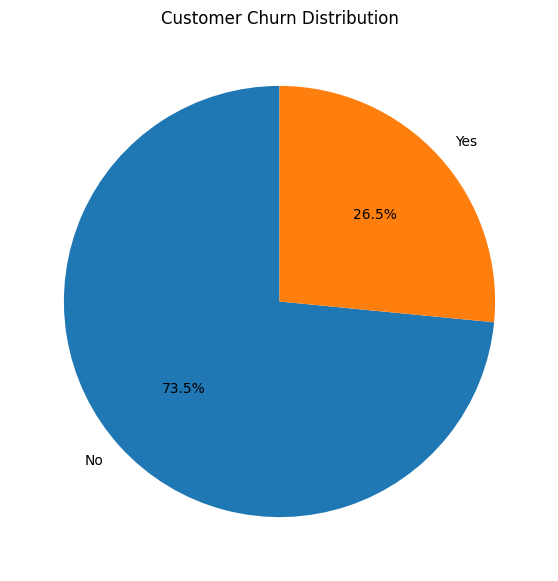

In [31]:
import matplotlib.pyplot as plt

# Count churn categories
churn_counts = df["Churn"].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

### 4.2 Contract Type vs Customer Churn

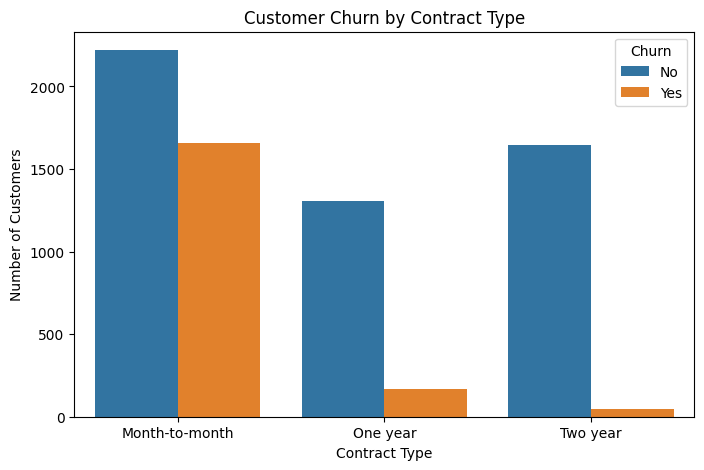

In [32]:


# Create a count plot
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

Customers with month-to-month contracts show the highest churn count, whereas customers with one-year and two-year contracts show much lower churn counts. This suggests that customers with longer-term contracts may be more likely to stay with the company.

### 4.3 Customer Tenure vs Churn

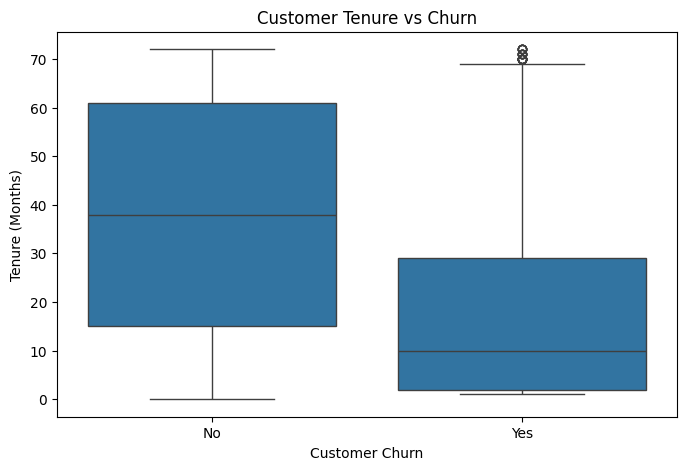

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

The box plot shows that customers who left the company generally had shorter tenure than customers who stayed. The median tenure of churned customers is approximately 10 months, while the median tenure of retained customers is approximately 38 months. This indicates that customer tenure may be an important factor in predicting churn.

### 4.4 Monthly Charges vs Customer Churn

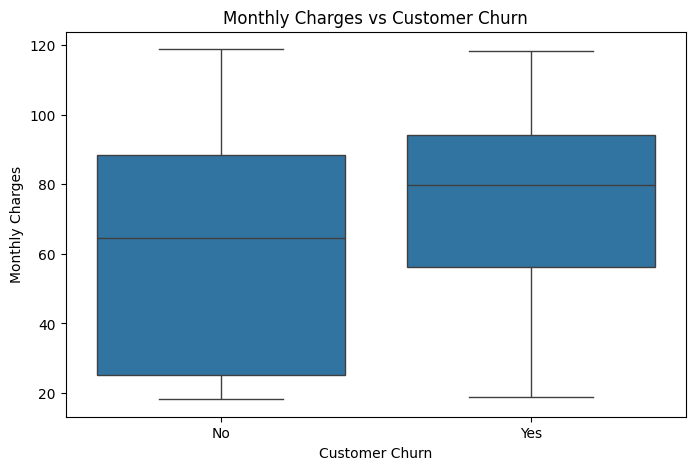

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

The box plot shows that customers who left the company generally paid higher monthly charges than customers who stayed. The median monthly charge for churned customers is approximately 80, compared to approximately 64 for retained customers. This suggests that monthly charges may be an important factor associated with customer churn.

In [35]:
# Display categorical columns
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns.tolist())

print("\nNumber of Categorical Columns:", len(categorical_columns))

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Number of Categorical Columns: 17


In [36]:
# Remove customerID and separate the target column
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())

Input Features Shape: (7043, 19)
Target Shape: (7043,)

Target Values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [37]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


In [38]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(include="object").columns
numerical_features = X_train.select_dtypes(exclude="object").columns

# Create the encoder
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

# Fit encoder on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Training Data after Encoding:", X_train_encoded.shape)
print("Testing Data after Encoding:", X_test_encoded.shape)

Training Data after Encoding: (5634, 45)
Testing Data after Encoding: (1409, 45)


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

# Create a weak learner
weak_learner = DecisionTreeClassifier(max_depth=1)

# Create AdaBoost model
ada_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

# Train the model
ada_model.fit(X_train_encoded, y_train)

print("AdaBoost Model Training Completed!")

AdaBoost Model Training Completed!


In [40]:
# Predict customer churn using test data
y_pred = ada_model.predict(X_test_encoded)

# Display actual and predicted values
print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

First 10 Actual Values:
[0 0 0 0 0 0 0 0 0 1]

First 10 Predicted Values:
[0 1 0 0 0 1 1 0 0 0]


In [41]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 80.0567778566359 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



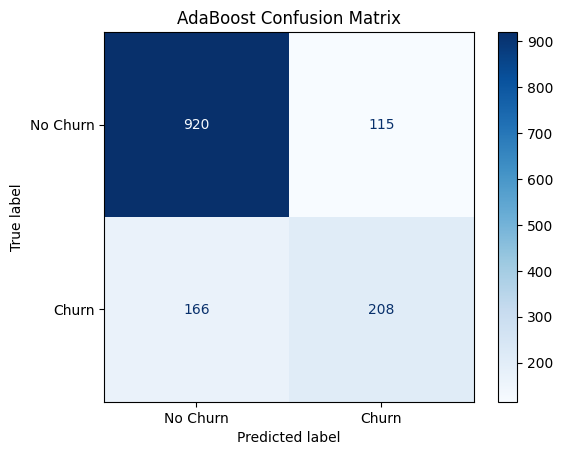

Confusion Matrix:
[[920 115]
 [166 208]]


In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("AdaBoost Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

The confusion matrix shows that the AdaBoost model correctly predicted 920 customers who stayed and 208 customers who left. However, it failed to identify 166 customers who actually left. This indicates that the model can identify retained customers better than churned customers.

In [43]:
# Create an improved AdaBoost model
ada_model_2 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train the improved model
ada_model_2.fit(X_train_encoded, y_train)

# Make predictions
y_pred_2 = ada_model_2.predict(X_test_encoded)

# Calculate accuracy
accuracy_2 = accuracy_score(y_test, y_pred_2)

print("Improved AdaBoost Accuracy:", accuracy_2 * 100, "%")

# Display classification report
print("\nImproved Classification Report:")
print(classification_report(y_test, y_pred_2))

Improved AdaBoost Accuracy: 79.347054648687 %

Improved Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



Two AdaBoost configurations were tested. The first model achieved 80.06% accuracy and a churn F1-score of 0.60, while the second model achieved 79.35% accuracy and an F1-score of 0.58. Therefore, the first configuration was selected.

In [44]:
import pandas as pd

# Get feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Model 1
importance = ada_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
print(feature_importance.head(10))

                                Feature  Importance
32         cat__Contract_Month-to-month    0.295400
42                    remainder__tenure    0.258060
12     cat__InternetService_Fiber optic    0.088158
33               cat__Contract_One year    0.070163
43            remainder__MonthlyCharges    0.050715
14               cat__OnlineSecurity_No    0.047384
39  cat__PaymentMethod_Electronic check    0.038122
31             cat__StreamingMovies_Yes    0.027041
44              remainder__TotalCharges    0.025816
8                 cat__MultipleLines_No    0.023735


### 4.5 Feature Importance Analysis

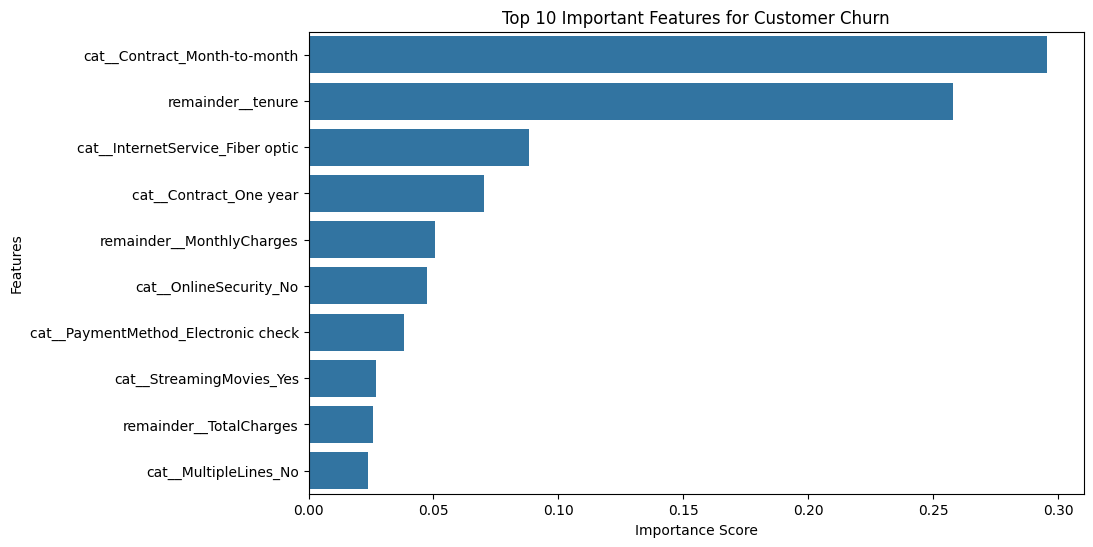

In [45]:
# Select the top 10 important features
top_features = feature_importance.head(10)

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Customer Churn")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

The feature importance analysis shows that month-to-month contracts have the highest importance score (0.2954), followed by customer tenure (0.2581). Fiber optic internet service, one-year contracts and monthly charges are also important features. This indicates that contract type and customer tenure play major roles in the model's churn predictions.

ROC-AUC Score: 0.8431656720659277


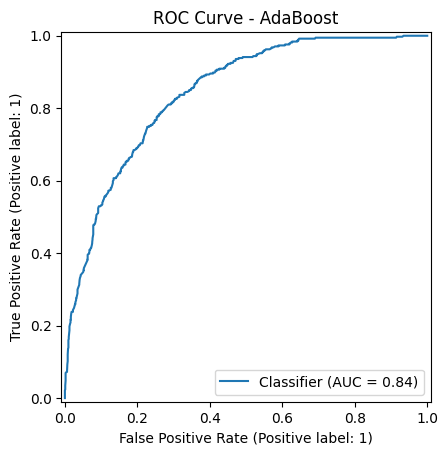

In [46]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict churn probabilities using Model 1
y_prob = ada_model.predict_proba(X_test_encoded)[:, 1]

# Calculate ROC-AUC score
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc_score)

# Plot ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - AdaBoost")
plt.show()

The ROC curve of the AdaBoost model achieved an AUC score of 0.84. This indicates that the model has good ability to distinguish between churn and non-churn customers. Therefore, the model demonstrates useful predictive performance on the testing dataset.

## 5. Conclusion

In this project, I developed an AdaBoost machine learning model to predict customer churn using the Telco Customer Churn dataset.

The dataset contained 7,043 customer records and 21 columns. Data cleaning was performed by converting TotalCharges into numerical format and handling 11 missing values. Exploratory Data Analysis was conducted using five visualizations to understand customer churn patterns.

The dataset was divided into 80% training data and 20% testing data. Categorical features were converted into numerical values using One-Hot Encoding. An AdaBoost classifier was trained using Decision Tree stumps as weak learners.

The first AdaBoost model achieved 80.06% accuracy, a churn F1-score of 0.60 and an ROC-AUC score of 0.84. Feature importance analysis showed that month-to-month contracts and customer tenure were the two most influential features.

This project helped me understand data preprocessing, visualization, Boosting algorithms and model evaluation. In the future, the model could be improved by experimenting with different parameters and techniques to identify more customers who are likely to leave.